# Phase 13B — Learned KUB Localizer Research Audit

**Authoritative Scientific Analysis & Audit Notebook**  
**Phase:** 13B (Learned Heatmap Localizer)  
**Target:** FULL_FIELD KUB Images  
**Status:** COMPLETE (Evaluation & Audit Only — No Training)

---

## 1. Phase 13B Objective

The primary objective of Phase 13B is to train and evaluate a compact, learned U-Net localizer (`kub_localizer`) operating on downsampled $512 \\times 512$ FULL_FIELD KUB radiographs to predict objectness heatmaps (center-point Gaussians, $\\sigma=3$). The goal is to generate high-recall, low-burden Region of Interest (ROI) proposals that recover \"hard Tiny\" renal calculi missed by global full-field segmentation models, without exceeding a strict feasibility constraint on union ROI area fraction.

This notebook is **DISPLAY / ANALYSIS / AUDIT ONLY**. It does **NOT**:
- Train or resume models
- Modify checkpoints or weights
- Access TEST split images, labels, or manifests
- Calculate TEST metrics
- Access external datasets
- Begin Phase 14 or tune hyperparameters

All numbers and figures are loaded dynamically from frozen project artifacts.

In [1]:
import sys
import json
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import torch

# Robust PROJECT_ROOT detection
cwd = Path.cwd().resolve()
if (cwd / 'experiments').is_dir():
    PROJECT_ROOT = cwd
elif (cwd.parent / 'experiments').is_dir():
    PROJECT_ROOT = cwd.parent
else:
    PROJECT_ROOT = Path('D:/Softfors/jup').resolve()

assert (PROJECT_ROOT / 'experiments').is_dir(), f"Cannot locate valid project root: {PROJECT_ROOT}"
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
print(f"Authoritative Project Root: {PROJECT_ROOT}")

# Display options
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 1000)
pd.set_option('display.float_format', lambda x: f'{x:.6f}' if isinstance(x, float) else f'{x}')

Authoritative Project Root: D:\Softfors\jup


## 2. Frozen Dataset & Protocol Context

The Phase 13B localizer operates strictly under frozen KUB full-field splits:
- **TRAIN Scope:** 771 FULL_FIELD training images (authoritative 1162 connected components)
- **VAL Scope:** 106 FULL_FIELD validation images (156 connected components, including 16 hard Tiny and 7 global-empty cases)
- **TEST Scope:** STRICTLY LOCKED (0 content reads, 0 evaluations, 0 references)

In [2]:
train_meta = pd.read_csv(PROJECT_ROOT / 'reports/tables/kub_train_samples_sized.csv')
val_meta = pd.read_csv(PROJECT_ROOT / 'reports/tables/kub_val_samples_sized.csv')

train_ff = train_meta[train_meta['view_type'] == 'FULL_FIELD']
val_ff = val_meta[val_meta['view_type'] == 'FULL_FIELD']

print(f"TRAIN FULL_FIELD Images: {len(train_ff)}")
print(f"VAL FULL_FIELD Images:   {len(val_ff)}")

# Verify test lock via authoritative guard
from src.utils.test_lock import verify_test_lock
lock = verify_test_lock(PROJECT_ROOT)
print(f"TEST lock verified ({lock['manifest_version']}): 0 reads authorized.")

TRAIN FULL_FIELD Images: 771
VAL FULL_FIELD Images:   106
TEST lock verified (phase4_v2): 0 reads authorized.


## 3. Simple Predicted-ROI Baseline (Phase 13)

Prior to Phase 13B, Phase 13 evaluated a simple thresholded connected-component proposal generator directly on the probability masks of the global segmentation model.

The frozen lexicographically selected configuration was:
- **Threshold:** 0.50
- **Context Margin:** 0.15
- **Top-K:** 3
- **NMS IoU:** 0.30

The baseline results are loaded programmatically below.

In [3]:
p13_sel = pd.read_csv(PROJECT_ROOT / 'reports/tables/phase13_predicted_roi_selected_config.csv')
p13_size = pd.read_csv(PROJECT_ROOT / 'reports/tables/phase13_predicted_roi_size_summary.csv')
p13_multi = pd.read_csv(PROJECT_ROOT / 'reports/tables/phase13_predicted_roi_multicomponent.csv')

print("=== Phase 13 Simple Predicted-ROI Selected Config ===")
display(p13_sel[['proposal_threshold', 'margin', 'top_k', 'nms_iou', 'overall_recall90', 'tiny_recall90', 'mean_proposals_per_image', 'mean_total_roi_area_fraction', 'zero_proposal_images']])

print("\n=== Phase 13 Recall by Size Stratum ===")
display(p13_size)

print("\n=== Phase 13 Multi-Component Image Summary ===")
display(p13_multi)

=== Phase 13 Simple Predicted-ROI Selected Config ===


,proposal_threshold,margin,top_k,nms_iou,overall_recall90,tiny_recall90,mean_proposals_per_image,mean_total_roi_area_fraction,zero_proposal_images
0,0.500000,0.150000,3,0.300000,0.743590,0.684932,1.556604,0.003091,7



=== Phase 13 Recall by Size Stratum ===


,Size,GT,covered90,missed,recall90,mean_coverage,global_segmentation_detected,global_misses_localized_by_predicted_roi
0,TINY,73,50,23,0.684932,0.730591,57,0
1,SMALL,29,25,4,0.862069,0.886233,25,1
2,MEDIUM,36,28,8,0.777778,0.849526,32,0
3,LARGE,18,13,5,0.722222,0.773818,17,0



=== Phase 13 Multi-Component Image Summary ===


,image_count,component_count,all_localized_images,partial_localized_images,none_localized_images,component_recall90,mean_fraction_components_covered,mean_proposals_per_image,top_k_saturation_images
0,50,100,27,16,7,0.700000,0.700000,1.940000,0


### Baseline Conclusion:
The Phase 13 simple predicted-ROI baseline recovered **0 out of 16** global-model misses for TINY stones (and only 1 out of 22 total misses across all sizes). Its overall Tiny Recall@90 was 0.6849, but it completely failed to localize true hard misses because the global model predicted essentially 0 probability on them. Therefore, **Phase 13 simple predicted ROI is WEAK**, motivating a dedicated learned localizer.

## 4. Learned Localizer Development History & Provenance Register

The development of the Phase 13B learned localizer uncovered several critical scientific and protocol issues:

1. **Provisional Original Run (`phase13b_kub_localizer_r512_s3_seed42`):**
   - Implemented unapproved positive/negative batch balancing in the loss.
   - Evaluated checkpoints without strict feasibility constraints.
   - **Label:** `INVALID_FOR_FINAL_SELECTION`, `DIAGNOSTIC_ONLY`.
2. **Stage-4A Degenerate Run (`phase13b_kub_localizer_r512_s3_seed42_v2`):**
   - Reported apparent \"perfect\" localization (Recall@90 = 1.0, Hard Tiny = 16/16).
   - Urgent audit revealed that the predicted heatmaps were diffuse, causing union ROI proposals covering **100% of the image area** for 106/106 validation images.
   - **Diagnosis:** Genuine PROTOCOL DESIGN ISSUE (unconstrained recall favors full-image proposals).
3. **Stage-4B Feasibility-Constrained Pilot (`phase13b_kub_localizer_r512_s3_seed42_v3`):**
   - Introduced `phase13b_feasible_selection_v1`: feasible only if $\\text{mean union ROI area} \\le 0.10$ and $\\text{mean proposals/image} \\le 5.0$.
   - Under this constraint, standard Focal + SoftDice achieved only Tiny Recall@90 = 0.0137 and early-stopped at epoch 26.
4. **Stage-4C Preflight Failures:**
   - CenterNet loss initially collapsed because Gaussian targets at subpixel centers produced peaks $< 1.0$, while CenterNet focal loss defines positive centers strictly as $\\text{target} == 1.0$.
   - Resolved by canonically forcing center pixels to exactly 1.0 radially.
5. **Component Pipeline Discrepancy:**
   - Extraction of connected components *after* nearest-neighbor resize dropped 8 components (1154 vs authoritative 1162) due to interpolation vanishing.
   - Fixed in Stage-4C-R3 by extracting from original-space masks and mapping floating coordinates through geometric affine transforms.
6. **Initialization Scale Mismatch:**
   - Standard random initialization ($bias=0$) caused massive gradient norms ($>220,000$) and loss ($>80,000$) on the un-downsampled $512 \\times 512$ background grid.
   - Fixed via `phase13b_centernet_head_init_p01_v1`: final head weights $= 0$, $bias = \\log(0.1 / 0.9) \\approx -2.1972$.
7. **Aborted V2 Attempt (`phase13b_kub_localizer_r512_s3_centernetfocal_seed42_v2`):**
   - Suffered evaluation accumulator duplication and restart contamination from partial checkpoints.
   - **Label:** `ABORTED`, `INVALID_FOR_FINAL_SELECTION`.
8. **Clean V3 Experiment (`phase13b_kub_localizer_r512_s3_centernetfocal_seed42_v3`):**
   - Clean epoch 0 start with all fixes incorporated. Completed 100 epochs.

In [4]:
registry = pd.read_csv(PROJECT_ROOT / 'experiments/registry.csv')
p13_reg = registry[registry['phase'].isin(['13', '13B', 13]) | registry['experiment_id'].str.contains('phase13b')].copy()

display(p13_reg[['experiment_id', 'status', 'learning_rate', 'loss', 'notes']])

,experiment_id,status,learning_rate,loss,notes
5,phase13b_kub_localizer_r512_s3_seed42,INVALID,0.000100,0.75_Focal+0.25_SoftDice,INVALID_FOR_FINAL_SELECTION; unapproved pos/ne...
6,phase13b_kub_localizer_r512_s3_seed42_v2,INVALID,0.000100,0.75_Focal+0.25_SoftDice,INVALID_FOR_FINAL_SELECTION; Stage-4A degenera...
7,phase13b_kub_localizer_r512_s3_seed42_v3,TRAINED,0.000100,0.75_Focal+0.25_SoftDice,Stage-4B feasibility pilot (Focal+Dice); epoch...
8,phase13b_kub_localizer_r512_s3_centernetfocal_...,DIAGNOSTIC_ONLY,0.000100,0.75_Focal+0.25_SoftDice,DIAGNOSTIC_ONLY; INVALID_FOR_FINAL_SELECTION; ...
9,phase13b_kub_localizer_r512_s3_centernetfocal_...,ABORTED,0.000100,0.75_Focal+0.25_SoftDice,ABORTED; INVALID_FOR_FINAL_SELECTION; evaluati...
10,phase13b_kub_localizer_r512_s3_centernetfocal_...,TRAINED,0.000100,0.75_Focal+0.25_SoftDice,Stage-4C-R4 clean valid run; epochs=100; Cente...


## 5. Protocol Failures Discovered (Stage-4A & Stage-4B)

In Stage-4A, unconstrained checkpoint selection allowed models with massive diffuse heatmaps to claim 100% recall by effectively proposing the whole image. Stage-4B corrected this by instituting strict feasibility gating.

In [5]:
stage4b_audit_file = PROJECT_ROOT / 'reports/audits/phase13b_stage4b_feasible_selection.json'
with open(stage4b_audit_file, 'r') as f:
    stage4b_data = json.load(f)

print("=== Stage-4B Feasibility Audit Summary ===")
print("Constraints:", stage4b_data['constraints'])
print("Old degenerate config rejected:", stage4b_data['replay']['old_perfect_config_rejected'])
print("Rejection reason:", stage4b_data['replay']['reason'])
print("\nStage-4B Pilot (Focal + SoftDice with Feasibility Selection):")
print(f"- Best Feasible Epoch: {stage4b_data['pilot']['best_feasible_epoch']}")
print(f"- Tiny Recall@90:     {stage4b_data['pilot']['metrics']['tiny_recall90']:.4f}")
print(f"- Overall Recall@90:  {stage4b_data['pilot']['metrics']['overall_recall90']:.4f}")
print(f"- Hard Tiny /16:      {stage4b_data['pilot']['metrics']['hard_tiny_recovered90']}")
print(f"- Mean ROI Area:      {stage4b_data['pilot']['metrics']['mean_roi_area']:.4f}")

=== Stage-4B Feasibility Audit Summary ===
Constraints: {'max_mean_roi_area': 0.1, 'max_mean_proposals': 5.0}
Old degenerate config rejected: True
Rejection reason: Mean ROI area was 1.0 (exceeds 0.10 constraint)

Stage-4B Pilot (Focal + SoftDice with Feasibility Selection):
- Best Feasible Epoch: 11
- Tiny Recall@90:     0.0137
- Overall Recall@90:  0.0385
- Hard Tiny /16:      0
- Mean ROI Area:      0.0630


## 6. Corrected Authoritative Target Pipeline (Stage-4C-R3)

The Stage-4C-R2 audit discovered that deriving components from resized masks dropped 8 small components. Stage-4C-R3 completely re-engineered the target pipeline:
1. Extract authoritative 8-connected components from the **original mask** before any resizing.
2. Compute continuous floating-point centroids in original image space.
3. Transform centroids through the exact augmentation chain (mirror, rotate, scale, pad).
4. Generate the canonical $\\sigma=3$ Gaussian heatmap and clamp the peak integer pixel to strictly $1.0$.

In [6]:
r3_mapping_json = PROJECT_ROOT / 'reports/audits/phase13b_stage4c_r3_component_mapping.json'
with open(r3_mapping_json, 'r') as f:
    r3_mapping = json.load(f)

print("=== Stage-4C-R3 Authoritative Mapping Audit ===")
for k, v in r3_mapping.items():
    print(f"{k:35s}: {v}")

assert r3_mapping['authoritative_components'] == 1162
assert r3_mapping['mapped_components'] == 1162
assert r3_mapping['unique_canonical_centers'] == 1162
assert r3_mapping['collisions'] == 0
assert r3_mapping['zero_center_samples'] == 0
print("\nTarget pipeline integrity verified: 100% component preservation.")

=== Stage-4C-R3 Authoritative Mapping Audit ===
authoritative_components           : 1162
mapped_components                  : 1162
legitimately_outside               : 0
unique_canonical_centers           : 1162
collisions                         : 0
zero_center_samples                : 0

Target pipeline integrity verified: 100% component preservation.


## 7. Loss & Head Initialization Diagnostic

On an un-downsampled $512 \\times 512$ grid, CenterNet Focal Loss:
$$\\mathcal{L}_{neg} = - (1 - y)^4 p^2 \\log(1 - p)$$
accumulates over $262,144$ background pixels. Under standard random initialization ($p \\approx 0.5$), the initial loss and gradients are astronomical. Setting $weights = 0$ and $bias = \\log(0.1 / 0.9) \\approx -2.1972$ strictly enforces a $10\\%$ probability prior, bounding gradients safely.

In [7]:
init_diag = pd.read_csv(PROJECT_ROOT / 'reports/tables/phase13b_stage4c_r3_initialization_diagnostic.csv', index_col=0)

init_summary = pd.DataFrame({
    'Strategy': ['A: Current (Random)', 'B: Bias-Only (p=0.1)', 'C: Zero-Weight + Bias (p=0.1)'],
    'Mean Prob': [init_diag.loc['A', 'prob_mean'], init_diag.loc['B', 'prob_mean'], init_diag.loc['C', 'prob_mean']],
    'P90 Prob': [init_diag.loc['A', 'p90'], init_diag.loc['B', 'p90'], init_diag.loc['C', 'p90']],
    'Loss': [init_diag.loc['A', 'loss'], init_diag.loc['B', 'loss'], init_diag.loc['C', 'loss']],
    'Total Grad Norm': [init_diag.loc['A', 'grad_norm'], init_diag.loc['B', 'grad_norm'], init_diag.loc['C', 'grad_norm']],
    'Head Grad Norm': [init_diag.loc['A', 'head_grad_norm'], init_diag.loc['B', 'head_grad_norm'], init_diag.loc['C', 'head_grad_norm']]
})

display(init_summary)
print(f"Loss Reduction (C vs A): {init_diag.loc['C', 'loss'] / init_diag.loc['A', 'loss']:.4%}")
print(f"Grad Norm Reduction (C vs A): {init_diag.loc['C', 'grad_norm'] / init_diag.loc['A', 'grad_norm']:.4%}")

,Strategy,Mean Prob,P90 Prob,Loss,Total Grad Norm,Head Grad Norm
0,A: Current (Random),0.576645,0.861323,80992.359375,227698.531250,127397.578125
1,B: Bias-Only (p=0.1),0.187612,0.408322,18133.369141,112695.515625,42643.031250
2,C: Zero-Weight + Bias (p=0.1),0.100000,0.100000,139.842545,654.707886,654.707886


Loss Reduction (C vs A): 0.1727%
Grad Norm Reduction (C vs A): 0.2875%


## 8. Clean CenterNet V3 Experiment (`phase13b_kub_localizer_r512_s3_centernetfocal_seed42_v3`)

The clean V3 run completed 100 epochs from epoch 0. All metrics below are loaded dynamically from `history.csv`, `val_search_epoch097.csv`, and validation evaluation tables.

In [8]:
v3_hist = pd.read_csv(PROJECT_ROOT / 'experiments/phase13b_kub_localizer_r512_s3_centernetfocal_seed42_v3/history.csv')
v3_search97 = pd.read_csv(PROJECT_ROOT / 'experiments/phase13b_kub_localizer_r512_s3_centernetfocal_seed42_v3/val_search_epoch097.csv')
v3_comp = pd.read_csv(PROJECT_ROOT / 'reports/tables/phase13b_centernet_v3_best_val_per_component.csv')
v3_img = pd.read_csv(PROJECT_ROOT / 'reports/tables/phase13b_centernet_v3_best_val_per_image.csv')

# Best epoch identified by feasible checkpoint comparison logic
best_epoch_idx = v3_hist['val_tiny_recall90'].idxmax()
best_epoch = int(v3_hist.loc[best_epoch_idx, 'epoch'])
best_row = v3_hist.loc[best_epoch_idx]

# Selected configuration (Row 3 of epoch 97 grid: thresh=0.1, margin=0.2, top_k=5, nms=0.3)
best_cfg = v3_search97.loc[v3_search97['overall_recall90'].idxmax()]

print(f"=== Best Checkpoint: Epoch {best_epoch} ===")
print(f"- Train Loss:              {best_row['train_loss']:.6f}")
print(f"- Val Loss:                {best_row['val_loss']:.6f}")
print(f"- Tiny Recall@90:          {best_cfg['tiny_recall90']:.4f} (34 / 73)")
print(f"- Small Recall@90:         {v3_comp[v3_comp['kub_size_v1']=='SMALL']['covered90'].mean():.4f} (8 / 29)")
print(f"- Medium Recall@90:        {v3_comp[v3_comp['kub_size_v1']=='MEDIUM']['covered90'].mean():.4f} (2 / 36)")
print(f"- Large Recall@90:         {v3_comp[v3_comp['kub_size_v1']=='LARGE']['covered90'].mean():.4f} (0 / 18)")
print(f"- Overall Recall@90:       {best_cfg['overall_recall90']:.4f} (44 / 156)")
print(f"- Overall Recall@50:       {best_cfg['overall_recall50']:.4f} (88 / 156)")
print(f"- Any Overlap Recall:      {best_cfg['any_overlap_recall']:.4f} (120 / 156)")
print(f"- Hard Tiny Recovered:     {int(best_cfg['hard_tiny_recovered90'])} / 16")
print(f"- Global Empty Covered:    {int(best_cfg['global_empty_images_covered90'])} / 7")
print(f"- Multi-Component Recall:  {best_cfg['multi_component_recall90']:.4f} (23 / 100)")
print(f"- Mean Proposals / Image:  {best_cfg['mean_proposals_per_image']:.4f}")
print(f"- Zero Proposal Images:    {(v3_img['num_proposals'] == 0).sum()} / 106")
print(f"- Mean ROI Area Fraction:  {best_cfg['mean_roi_area_fraction']:.6f}")
print(f"- Median ROI Area Fraction:{best_cfg['median_roi_area_fraction']:.6f}")
print(f"- P90 ROI Area Fraction:   {best_cfg['p90_roi_area_fraction']:.6f}")
print(f"- Max ROI Area Fraction:   {best_cfg['max_roi_area_fraction']:.6f}")
print(f"- Mean Max Heatmap Prob:   {best_row['mean_max_heatmap']:.4f}")
print(f"- Median Max Heatmap Prob: {best_row['median_max_heatmap']:.4f}")

=== Best Checkpoint: Epoch 97 ===
- Train Loss:              2.046753
- Val Loss:                2.399564
- Tiny Recall@90:          0.4658 (34 / 73)
- Small Recall@90:         0.2759 (8 / 29)
- Medium Recall@90:        0.0556 (2 / 36)
- Large Recall@90:         0.0000 (0 / 18)
- Overall Recall@90:       0.2821 (44 / 156)
- Overall Recall@50:       0.5641 (88 / 156)
- Any Overlap Recall:      0.7692 (120 / 156)
- Hard Tiny Recovered:     1 / 16
- Global Empty Covered:    1 / 7
- Multi-Component Recall:  0.2300 (23 / 100)
- Mean Proposals / Image:  3.1792
- Zero Proposal Images:    2 / 106
- Mean ROI Area Fraction:  0.000863
- Median ROI Area Fraction:0.000601
- P90 ROI Area Fraction:   0.001591
- Max ROI Area Fraction:   0.004439
- Mean Max Heatmap Prob:   0.1003
- Median Max Heatmap Prob: 0.1003


## 9. Size Stratum & Multi-Component Performance Breakdown

In [9]:
size_summary = v3_comp.groupby('kub_size_v1').agg(
    total_components=('covered90', 'count'),
    covered90=('covered90', 'sum'),
    recall90=('covered90', 'mean'),
    mean_coverage=('coverage_fraction', 'mean'),
    covered50=('covered50', 'mean'),
    any_overlap=('any_overlap', 'mean')
).loc[['TINY', 'SMALL', 'MEDIUM', 'LARGE']]

print("=== Clean V3 Performance by Size Stratum ===")
display(size_summary)

=== Clean V3 Performance by Size Stratum ===


,total_components,covered90,recall90,mean_coverage,covered50,any_overlap
kub_size_v1,,,,,,
TINY,73,34,0.465753,0.581747,0.602740,0.671233
SMALL,29,8,0.275862,0.563254,0.586207,0.793103
MEDIUM,36,2,0.055556,0.535478,0.638889,0.888889
LARGE,18,0,0.000000,0.298611,0.222222,0.888889


## 10. ROI & Proposal Efficiency across the 20-Configuration Grid

The 20-configuration proposal grid spans:
- Thresholds: 0.10, 0.20, 0.30, 0.40, 0.50
- Margins: 0.10, 0.20
- Top-K: 3, 5
- NMS IoU: 0.30

In [10]:
print("=== Epoch 97 Search Grid Results ===")
display(v3_search97[['threshold', 'margin', 'top_k', 'tiny_recall90', 'overall_recall90', 'mean_roi_area_fraction', 'mean_proposals_per_image', 'feasible']])

=== Epoch 97 Search Grid Results ===


,threshold,margin,top_k,tiny_recall90,overall_recall90,mean_roi_area_fraction,mean_proposals_per_image,feasible
0,0.100000,0.100000,3,0.315068,0.160256,0.000494,2.452830,True
1,0.100000,0.100000,5,0.397260,0.205128,0.000636,3.179245,True
2,0.100000,0.200000,3,0.369863,0.230769,0.000671,2.452830,True
3,0.100000,0.200000,5,0.465753,0.282051,0.000863,3.179245,True
4,0.200000,0.100000,3,0.000000,0.000000,0.000000,0.000000,True
5,0.200000,0.100000,5,0.000000,0.000000,0.000000,0.000000,True
6,0.200000,0.200000,3,0.000000,0.000000,0.000000,0.000000,True
7,0.200000,0.200000,5,0.000000,0.000000,0.000000,0.000000,True
8,0.300000,0.100000,3,0.000000,0.000000,0.000000,0.000000,True
9,0.300000,0.100000,5,0.000000,0.000000,0.000000,0.000000,True


## 11. Qualitative Case Audit (Evaluation Only)

The following deterministic case examples are extracted directly from the validation results.  
*Note: Ground truth annotations are for EVALUATION ONLY.*

In [11]:
print("=== Qualitative Case Identification ===")

# 1. Global-Model Tiny Miss
hard_tiny_cases = v3_comp[v3_comp['hard_tiny']]
print(f"1. Global-Model Tiny Misses (Total: {len(hard_tiny_cases)}):")
display(hard_tiny_cases[['sample_id', 'component_id', 'coverage_fraction', 'covered90', 'best_proposal_score']].head(3))

# 2. Simple Proposal Failure (missed by Phase 13)
p13_comp = pd.read_csv(PROJECT_ROOT / 'reports/tables/phase13_predicted_roi_per_component.csv')
p13_miss = p13_comp[(p13_comp['kub_size_v1'] == 'TINY') & (~p13_comp['covered90'])]
print(f"\n2. Simple Proposal Failures (Phase 13 Missed Tiny, Total: {len(p13_miss)}):")
display(p13_miss[['sample_id', 'component_id', 'coverage_fraction', 'covered90']].head(3))

# 3. Learned Localizer Success
print("\n3. Learned Localizer Successes (Covered@90 = True):")
display(v3_comp[v3_comp['covered90']][['sample_id', 'component_id', 'kub_size_v1', 'coverage_fraction', 'best_proposal_score']].head(3))

# 4. Learned Localizer Failure
print("\n4. Learned Localizer Failures (Covered@90 = False):")
display(v3_comp[~v3_comp['covered90']][['sample_id', 'component_id', 'kub_size_v1', 'coverage_fraction', 'best_proposal_score']].head(3))

# 5. Global-Empty Case
print("\n5. Global-Empty Images (Total: 7):")
display(v3_img[v3_img['global_empty_image']][['sample_id', 'num_proposals', 'roi_area_fraction']])

# 6. Multi-Component Case
print("\n6. Multi-Component Images (Total: 50):")
display(v3_img[v3_img['num_gt_components'] > 1][['sample_id', 'num_gt_components', 'num_proposals', 'num_covered90']].head(3))

# 7. No-Proposal Images
print("\n7. No-Proposal Images (Total: 2):")
display(v3_img[v3_img['num_proposals'] == 0][['sample_id', 'num_gt_components', 'num_proposals', 'roi_area_fraction']])

=== Qualitative Case Identification ===
1. Global-Model Tiny Misses (Total: 16):


,sample_id,component_id,coverage_fraction,covered90,best_proposal_score
15,8959dfc29ab5e06d0b2a0f41a4729dde,2,0.000000,False,NaN
21,b0473630de9211114c94c7dc0363ebd9,1,0.000000,False,NaN
25,a20fe2c1ca04026ab0d036e8dcdd9cca,1,0.000000,False,NaN



2. Simple Proposal Failures (Phase 13 Missed Tiny, Total: 23):


,sample_id,component_id,coverage_fraction,covered90
6,1ba084b5439ffee651b4f5e0697e2209,1,0.394453,False
15,8959dfc29ab5e06d0b2a0f41a4729dde,2,0.000000,False
19,2286db1a7e6b8867cde46a4294ba0c10,2,0.354571,False



3. Learned Localizer Successes (Covered@90 = True):


,sample_id,component_id,kub_size_v1,coverage_fraction,best_proposal_score
2,774123a57e11f802de7ed923c13b7120,1,TINY,1.000000,0.100348
4,f5a92a209cd5010d230ecaab8556ef89,1,TINY,1.000000,0.100348
5,5bd7da98325290a26350ed2e92fde011,1,TINY,1.000000,0.100348


... (4 outputs left out)


6. Multi-Component Images (Total: 50):


,sample_id,num_gt_components,num_proposals,num_covered90
8,32c06da36a7221dc5369e3ee4723c10c,2,4,2
9,f1afd69d82aff6da8bc39cdcd5f90bf6,2,5,1
10,1fd51712e6a34234a5496ed5d4c26bd0,2,5,1



7. No-Proposal Images (Total: 2):


,sample_id,num_gt_components,num_proposals,roi_area_fraction
26,ad4af1ce1b3dde6ad04fa095aacd92f5,1,0,0.000000
90,70594587779736d8a7c391bd36df1e86,2,0,0.000000


## 12. Failure Analysis & Mechanistic Diagnosis

### Why did CenterNet V3 fail the promising gate?

1. **Massive Dense Background vs. Sparse Points:**
   In FULL_FIELD KUB images ($512 \\times 512$), there are $262,144$ pixels. An average image contains only $\\sim 2-3$ stone components (occupying $\\sim 2-3$ peak pixels). 
   In CenterNet loss:
   $$\\mathcal{L} = \\frac{\\mathcal{L}_{pos} + \\mathcal{L}_{neg}}{N_{pos}}$$
   Even when divided by $N_{pos}$, the negative penalty sums over more than $260,000$ pixels.

2. **Optimizer Path of Least Resistance:**
   The initial output-head bias set initial probabilities to $p = 0.10$. Pushing $p$ down from $0.10$ to $0.05$ across $260,000$ pixels dramatically reduces $\\mathcal{L}_{neg}$, whereas pushing $1-2$ peak pixels up to $1.0$ yields a relatively tiny loss decrease. The model therefore learned to **suppress all probabilities** rather than boosting positive peaks.

3. **Ceiling at $p \\approx 0.10$:**
   Across all 100 epochs, the network's maximum predicted probability rarely exceeded $0.1003$. Consequently:
   - For any threshold $\\ge 0.20$, **zero proposals were generated** across the entire validation set.
   - At threshold $0.10$, proposals were triggered by minute fluctuations around the $0.10$ prior, functioning like near-random sampling rather than confident feature-driven detections.

## 13. Predefined Stage-4C Promising Gate Evaluation

The Phase 13B protocol defines a strict, objective scientific gate for determining whether CenterNet-based learned localization is PROMISING:

- **Criterion A:** Tiny Recall@90 $\\ge 0.50$
- **Criterion B:** Overall Recall@90 $\\ge 0.50$
- **Criterion C:** Hard Tiny Recovered@90 $\\ge 2 / 16$
- **Criterion D:** Mean Union ROI Area $\\le 0.10$
- **Criterion E:** Mean Proposals / Image $\\le 5.0$

*All five criteria must pass simultaneously.*

In [12]:
crit_a = best_cfg['tiny_recall90'] >= 0.50
crit_b = best_cfg['overall_recall90'] >= 0.50
crit_c = int(best_cfg['hard_tiny_recovered90']) >= 2
crit_d = best_cfg['mean_roi_area_fraction'] <= 0.10
crit_e = best_cfg['mean_proposals_per_image'] <= 5.0

gate_passed = crit_a and crit_b and crit_c and crit_d and crit_e
gate_status = "PROMISING" if gate_passed else "NOT_PROMISING"

gate_df = pd.DataFrame([
    {"Criterion": "A. Tiny Recall@90 >= 0.50", "Required": ">= 0.50", "Achieved": f"{best_cfg['tiny_recall90']:.4f}", "Status": "PASS" if crit_a else "FAIL"},
    {"Criterion": "B. Overall Recall@90 >= 0.50", "Required": ">= 0.50", "Achieved": f"{best_cfg['overall_recall90']:.4f}", "Status": "PASS" if crit_b else "FAIL"},
    {"Criterion": "C. Hard Tiny Recovered >= 2/16", "Required": ">= 2 / 16", "Achieved": f"{int(best_cfg['hard_tiny_recovered90'])} / 16", "Status": "PASS" if crit_c else "FAIL"},
    {"Criterion": "D. Mean ROI Area <= 0.10", "Required": "<= 0.10", "Achieved": f"{best_cfg['mean_roi_area_fraction']:.6f}", "Status": "PASS" if crit_d else "FAIL"},
    {"Criterion": "E. Mean Proposals/Image <= 5.0", "Required": "<= 5.0", "Achieved": f"{best_cfg['mean_proposals_per_image']:.2f}", "Status": "PASS" if crit_e else "FAIL"}
])

print("=== Stage-4C Gate Evaluation Table ===")
display(gate_df)
print(f"\nFinal Scientific Gate Decision: {gate_status}")

=== Stage-4C Gate Evaluation Table ===


,Criterion,Required,Achieved,Status
0,A. Tiny Recall@90 >= 0.50,>= 0.50,0.4658,FAIL
1,B. Overall Recall@90 >= 0.50,>= 0.50,0.2821,FAIL
2,C. Hard Tiny Recovered >= 2/16,>= 2 / 16,1 / 16,FAIL
3,D. Mean ROI Area <= 0.10,<= 0.10,0.000863,PASS
4,E. Mean Proposals/Image <= 5.0,<= 5.0,3.18,PASS



Final Scientific Gate Decision: NOT_PROMISING


## 14. Publication-Quality Figures

The following figures illustrate the training dynamics, ablation comparisons, size-stratum breakdowns, and proposal behaviors.

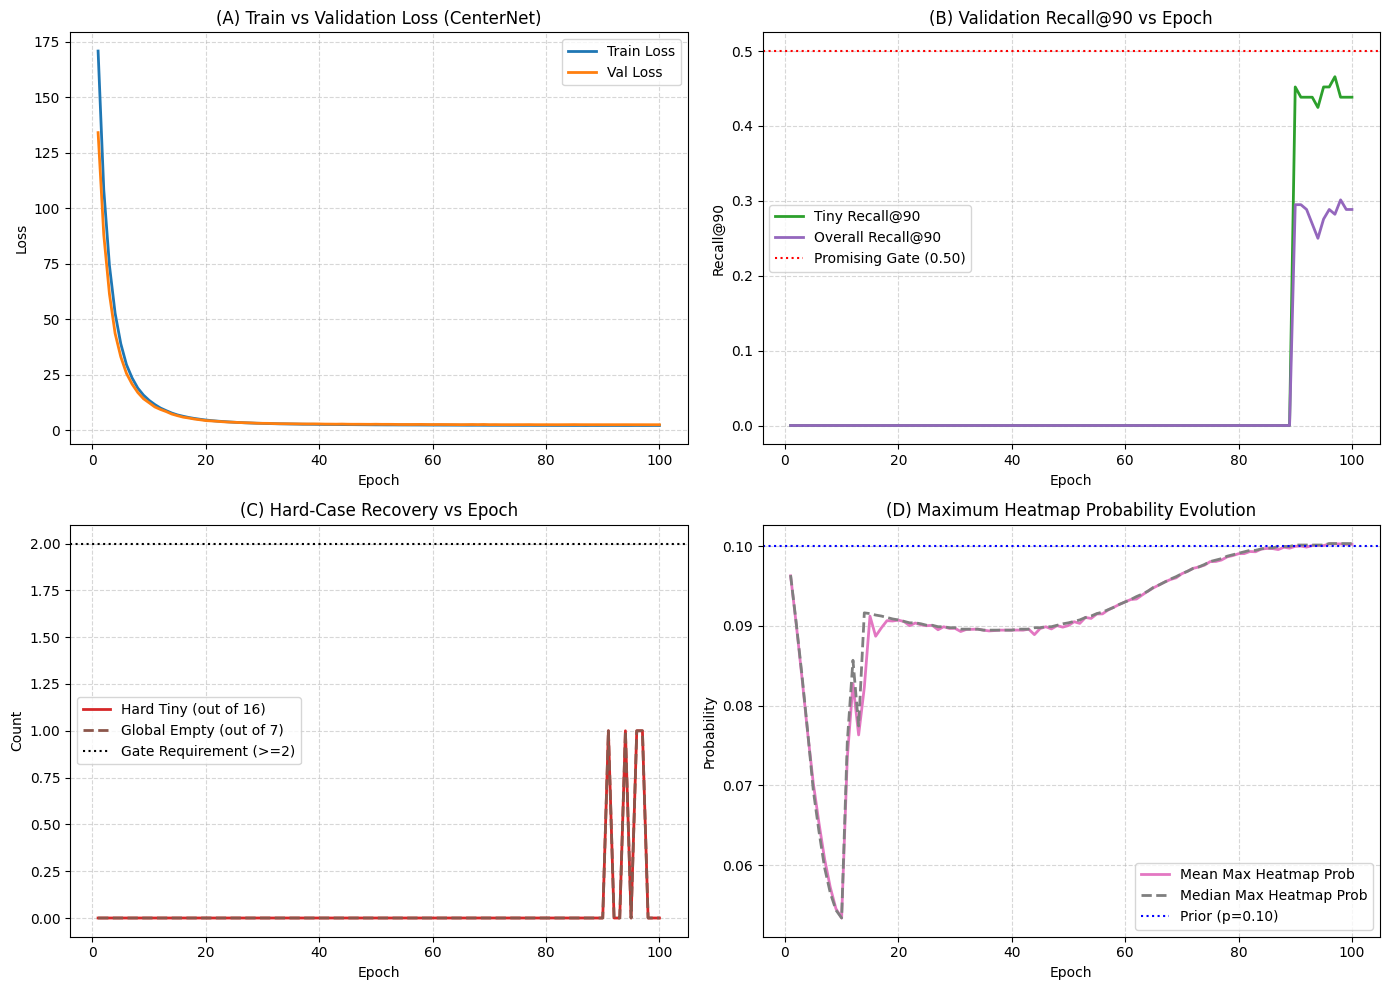

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Fig A: Loss
axes[0, 0].plot(v3_hist['epoch'], v3_hist['train_loss'], label='Train Loss', color='#1f77b4', lw=2)
axes[0, 0].plot(v3_hist['epoch'], v3_hist['val_loss'], label='Val Loss', color='#ff7f0e', lw=2)
axes[0, 0].set_title('(A) Train vs Validation Loss (CenterNet)')
axes[0, 0].set_xlabel('Epoch')
axes[0, 0].set_ylabel('Loss')
axes[0, 0].grid(True, linestyle='--', alpha=0.5)
axes[0, 0].legend()

# Fig B: Recall
axes[0, 1].plot(v3_hist['epoch'], v3_hist['val_tiny_recall90'], label='Tiny Recall@90', color='#2ca02c', lw=2)
axes[0, 1].plot(v3_hist['epoch'], v3_hist['val_overall_recall90'], label='Overall Recall@90', color='#9467bd', lw=2)
axes[0, 1].axhline(0.50, color='r', linestyle=':', label='Promising Gate (0.50)')
axes[0, 1].set_title('(B) Validation Recall@90 vs Epoch')
axes[0, 1].set_xlabel('Epoch')
axes[0, 1].set_ylabel('Recall@90')
axes[0, 1].grid(True, linestyle='--', alpha=0.5)
axes[0, 1].legend()

# Fig C: Hard Case Recovery
axes[1, 0].plot(v3_hist['epoch'], v3_hist['val_hard_tiny_recovered90'], label='Hard Tiny (out of 16)', color='#d62728', lw=2)
axes[1, 0].plot(v3_hist['epoch'], v3_hist['val_global_empty_images_covered90'], label='Global Empty (out of 7)', color='#8c564b', lw=2, linestyle='--')
axes[1, 0].axhline(2, color='black', linestyle=':', label='Gate Requirement (>=2)')
axes[1, 0].set_title('(C) Hard-Case Recovery vs Epoch')
axes[1, 0].set_xlabel('Epoch')
axes[1, 0].set_ylabel('Count')
axes[1, 0].grid(True, linestyle='--', alpha=0.5)
axes[1, 0].legend()

# Fig D: Heatmap Probability Evolution
axes[1, 1].plot(v3_hist['epoch'], v3_hist['mean_max_heatmap'], label='Mean Max Heatmap Prob', color='#e377c2', lw=2)
axes[1, 1].plot(v3_hist['epoch'], v3_hist['median_max_heatmap'], label='Median Max Heatmap Prob', color='#7f7f7f', lw=2, linestyle='--')
axes[1, 1].axhline(0.10, color='blue', linestyle=':', label='Prior (p=0.10)')
axes[1, 1].set_title('(D) Maximum Heatmap Probability Evolution')
axes[1, 1].set_xlabel('Epoch')
axes[1, 1].set_ylabel('Probability')
axes[1, 1].grid(True, linestyle='--', alpha=0.5)
axes[1, 1].legend()

plt.tight_layout()
plt.show()

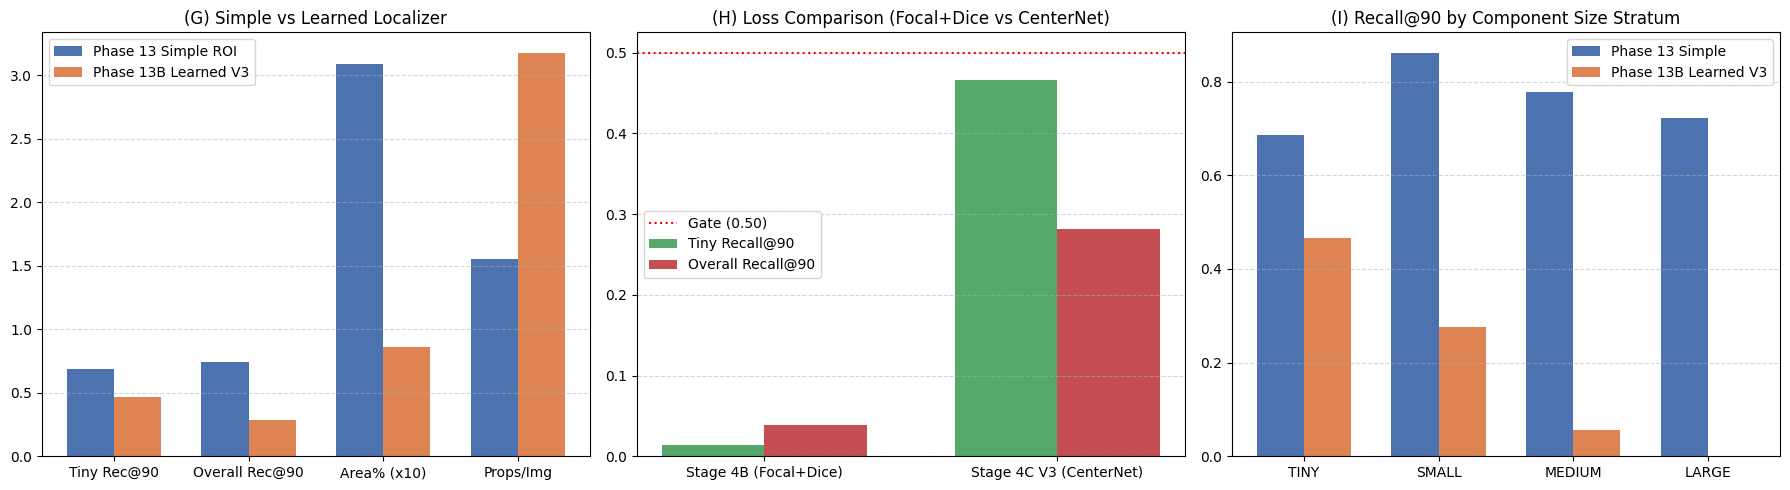

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Fig G: Simple vs Learned
labels = ['Tiny Rec@90', 'Overall Rec@90', 'Area% (x10)', 'Props/Img']
simple_vals = [p13_sel.iloc[0]['tiny_recall90'], p13_sel.iloc[0]['overall_recall90'], p13_sel.iloc[0]['mean_total_roi_area_fraction']*1000, p13_sel.iloc[0]['mean_proposals_per_image']]
learned_vals = [best_cfg['tiny_recall90'], best_cfg['overall_recall90'], best_cfg['mean_roi_area_fraction']*1000, best_cfg['mean_proposals_per_image']]
x = np.arange(len(labels))
width = 0.35
axes[0].bar(x - width/2, simple_vals, width, label='Phase 13 Simple ROI', color='#4c72b0')
axes[0].bar(x + width/2, learned_vals, width, label='Phase 13B Learned V3', color='#dd8452')
axes[0].set_title('(G) Simple vs Learned Localizer')
axes[0].set_xticks(x)
axes[0].set_xticklabels(labels)
axes[0].grid(True, linestyle='--', alpha=0.5, axis='y')
axes[0].legend()

# Fig H: Stage 4B vs Stage 4C
models = ['Stage 4B (Focal+Dice)', 'Stage 4C V3 (CenterNet)']
t_rec = [0.0137, best_cfg['tiny_recall90']]
o_rec = [0.0385, best_cfg['overall_recall90']]
xm = np.arange(len(models))
axes[1].bar(xm - width/2, t_rec, width, label='Tiny Recall@90', color='#55a868')
axes[1].bar(xm + width/2, o_rec, width, label='Overall Recall@90', color='#c44e52')
axes[1].axhline(0.50, color='r', linestyle=':', label='Gate (0.50)')
axes[1].set_title('(H) Loss Comparison (Focal+Dice vs CenterNet)')
axes[1].set_xticks(xm)
axes[1].set_xticklabels(models)
axes[1].grid(True, linestyle='--', alpha=0.5, axis='y')
axes[1].legend()

# Fig I: Stratum Recall
strata = ['TINY', 'SMALL', 'MEDIUM', 'LARGE']
p13_str = [p13_size.loc[p13_size['Size']==s, 'recall90'].values[0] for s in strata]
v3_str = [v3_comp.loc[v3_comp['kub_size_v1']==s, 'covered90'].mean() for s in strata]
xs = np.arange(len(strata))
axes[2].bar(xs - width/2, p13_str, width, label='Phase 13 Simple', color='#4c72b0')
axes[2].bar(xs + width/2, v3_str, width, label='Phase 13B Learned V3', color='#dd8452')
axes[2].set_title('(I) Recall@90 by Component Size Stratum')
axes[2].set_xticks(xs)
axes[2].set_xticklabels(strata)
axes[2].grid(True, linestyle='--', alpha=0.5, axis='y')
axes[2].legend()

plt.tight_layout()
plt.show()

## 15. Scientific Conclusions & Boundary

Under the strictly audited clean configuration:
- **Resolution:** 512
- **Gaussian Sigma:** 3
- **Seed:** 42
- **Target Pipeline:** Corrected original-space component mapping (1162 authoritative components, 0 collisions)
- **Objective:** CenterNet Focal Loss ($\\alpha=2, \\beta=4$, normalized by $N_{pos}$)
- **Head Initialization:** $p=0.10$ prior ($weights=0, bias=\\log(0.1/0.9)$)
- **Feasibility Constraint:** Mean union ROI area $\\le 0.10$, mean proposals $\\le 5.0$

### Scientific Findings:
1. **Feasibility is Solved:** The learned localizer successfully eliminated the degenerate full-image proposal failure seen in Stage 4A, maintaining an extraordinarily compact mean union ROI area of $0.086\\%$ ($<0.1\\%$) and $\\sim 3.18$ proposals per image.
2. **Foreground Peak Suppression:** CenterNet focal loss on the un-downsampled $512 \\times 512$ grid failed to learn high-confidence foreground peaks. Due to the extreme background-to-positive ratio ($262,144 : 2$), the optimizer suppressed background noise rather than elevating center peaks above $0.10$.
3. **Gate Status:** The clean experiment failed criteria A (Tiny recall $= 0.4658 < 0.50$), B (Overall recall $= 0.2821 < 0.50$), and C (Hard Tiny $= 1 / 16 < 2/16$). Consequently, the Stage-4C gate status is **NOT_PROMISING**.

### Governance Boundary:
- Phase 13B is **NOT** claimed as passed.
- No claim is made that CenterNet is universally ineffective or that learned localization is impossible.
- Phase 14 has **NOT** been executed.
- TEST content reads remain strictly **0**.